# Conformal prediction intervals

Calibrate prediction intervals from **cross-validation errors on the point forecast** instead of a model's
native quantile head. Set a [`ConformalIntervals`](../conformal-prediction.md) object on any model and pass
`level` (or `quantiles`) to `forecast()` as usual. See [Conformal prediction](../conformal-prediction.md)
for the full API.

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

**Dataset:** hourly day-ahead electricity prices for five markets (BE, DE, FR, NP, PJM), the same panel as
the [exogenous variables](exogenous-variables.ipynb) example. We only use the target here. Horizon length is
**24 hours** (`h=24`).

**How it works:** For every `unique_id`, FoundationForecast backtests the model's point forecast over
`n_windows` rolling windows of length `h` at the end of the history and stores the absolute errors per
horizon step. The final point forecast is then widened with those errors:

- **`conformal_distribution`** (default) builds synthetic paths `forecast ± error` and takes symmetric quantiles.
- **`conformal_error`** adds and subtracts the `level` quantile of the absolute errors per horizon step.

Intervals are calibrated **per series** and **per horizon step**, so a series whose forecasts were hard to get
right gets wider bands, and later steps usually get wider bands than earlier ones.

**Models in this example:** **Tafsut** and **Chronos-2**, each twice: once with native quantiles and once with
conformal intervals, so we can compare coverage on the same point forecasts.

**Caveats:**
- Calibration costs about **`n_windows` extra forecasts per series**, on top of the final forecast.
- Each series needs at least **`n_windows * h + 1`** observations.
- `prediction_intervals` only changes **`forecast()`**. `cross_validation()` and `detect_anomalies()` keep
  using native quantiles, so this notebook evaluates conformal intervals with a manual holdout loop.

## Import libraries

In [2]:
import pandas as pd

from foundationforecast import ConformalIntervals, FoundationForecast

## Load the dataset

The DataFrame must include at least the following columns:
- `unique_id`: series identifier (string)
- `ds`: timestamp (datetime)
- `y`: target (float)

The source file also ships two exogenous columns. We drop them to keep this example univariate.

The pandas frequency is inferred from `ds` when `freq` is omitted.

In [3]:
DATA = "https://timecopilot.s3.amazonaws.com/public/data/electricity_price"
df = pd.read_parquet(f"{DATA}/train.parquet")[["unique_id", "ds", "y"]]
df.head()

,unique_id,ds,y
0,BE,2011-01-09 00:00:00,32.540001
1,BE,2011-01-09 01:00:00,21.549999
2,BE,2011-01-09 02:00:00,15.710000
3,BE,2011-01-09 03:00:00,10.580000
4,BE,2011-01-09 04:00:00,10.320000


## Plot the data

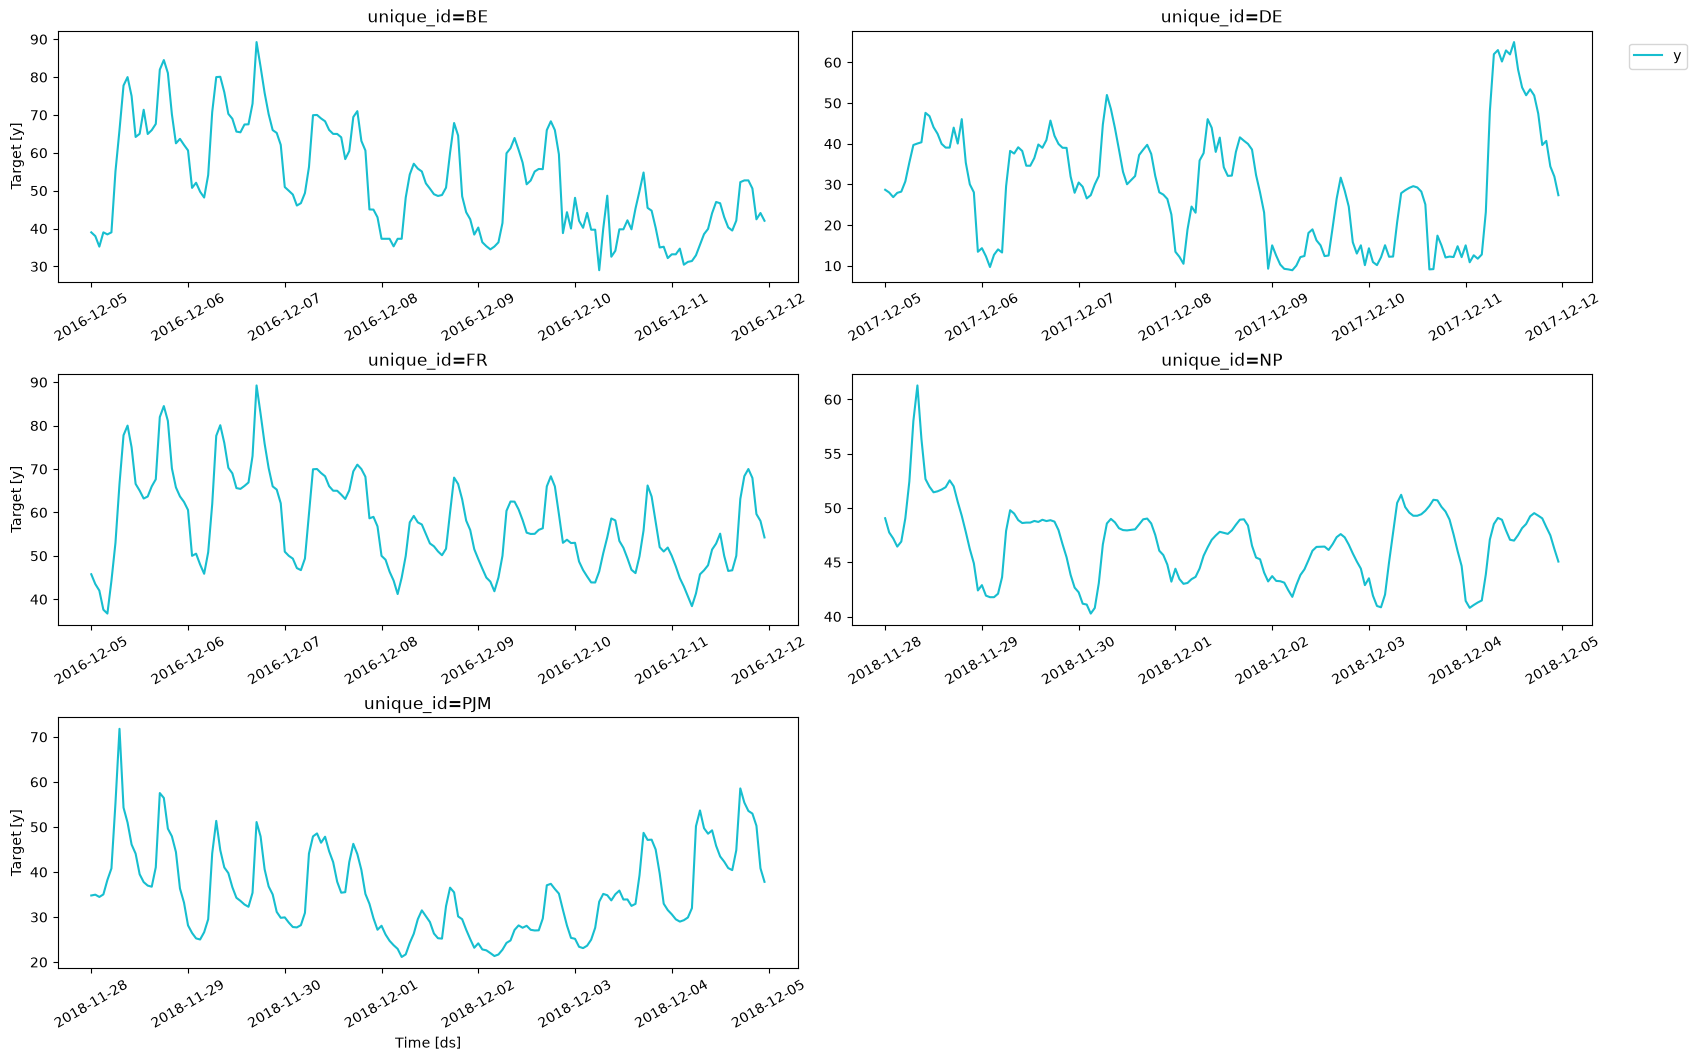

In [4]:
FoundationForecast.plot(df, max_insample_length=24 * 7)

## Import the models

In [5]:
from foundationforecast.models import Chronos, Tafsut

## Create a FoundationForecast

Each model appears twice with a distinct **`alias`**. The `-conformal` copies get a `ConformalIntervals`
object on **`prediction_intervals`**; the others keep their native quantiles.

`n_windows=7` calibrates on the last seven days of each series (one window per day at `h=24`). More windows
give smoother interval estimates at the cost of more forecasts. `h` is taken from `forecast(h=...)`.

In [6]:
def conformal(model, n_windows=7):
    model.prediction_intervals = ConformalIntervals(n_windows=n_windows)
    return model


models = [
    Tafsut(alias="Tafsut", context_length=2048),
    conformal(Tafsut(alias="Tafsut-conformal", context_length=2048)),
    Chronos(repo_id="amazon/chronos-2", alias="Chronos-2"),
    conformal(Chronos(repo_id="amazon/chronos-2", alias="Chronos-2-conformal")),
]

ff = FoundationForecast(models=models)

## Holdout evaluation

Because `cross_validation()` does not apply conformal calibration, we backtest by hand: cut the last
`n_cutoffs` days off each series, call `forecast()` on what remains, and join the actuals back. Each call
recalibrates the conformal models on data before its cutoff only, so there is no leakage.

In [7]:
h = 24
level = [80, 90]
n_cutoffs = 4

actuals = df[["unique_id", "ds", "y"]]
holdout = []
for k in range(n_cutoffs, 0, -1):
    train = df.groupby("unique_id").head(-h * k)
    cutoffs = train.groupby("unique_id")["ds"].max().rename("cutoff").reset_index()
    fcst = ff.forecast(df=train, h=h, level=level)
    holdout.append(fcst.merge(cutoffs, on="unique_id").merge(actuals, on=["unique_id", "ds"]))

holdout_df = pd.concat(holdout, ignore_index=True)
holdout_df.head()

,unique_id,ds,Tafsut,Tafsut-lo-80,Tafsut-hi-80,Tafsut-lo-90,Tafsut-hi-90,Tafsut-conformal,Tafsut-conformal-lo-90,Tafsut-conformal-lo-80,...,Chronos-2-hi-80,Chronos-2-lo-90,Chronos-2-hi-90,Chronos-2-conformal,Chronos-2-conformal-lo-90,Chronos-2-conformal-lo-80,Chronos-2-conformal-hi-80,Chronos-2-conformal-hi-90,cutoff,y
0,BE,2016-12-08 00:00:00,40.039978,36.314823,43.487221,36.314823,43.487221,40.039978,19.052773,22.524896,...,40.555069,33.329926,42.366402,37.450851,15.772379,18.371761,56.529942,59.129324,2016-12-07 23:00:00,37.299999
1,BE,2016-12-08 01:00:00,37.768410,33.818840,42.409855,33.818840,42.409855,37.768410,19.551207,23.763879,...,38.725262,30.631063,40.568981,35.161568,15.752480,19.298424,51.024711,54.570655,2016-12-07 23:00:00,37.299999
2,BE,2016-12-08 02:00:00,35.511082,31.950052,39.778343,31.950052,39.778343,35.511082,19.232742,23.219197,...,37.615654,28.912966,39.618790,33.820194,18.977901,23.819759,43.820629,48.662488,2016-12-07 23:00:00,37.299999
3,BE,2016-12-08 03:00:00,33.560028,30.430708,38.491066,30.430708,38.491066,33.560028,21.307850,23.732110,...,36.959770,27.454578,39.014839,32.789059,21.320639,23.341325,42.236792,44.257479,2016-12-07 23:00:00,35.299999
4,BE,2016-12-08 04:00:00,33.446732,29.964645,38.431580,29.964645,38.431580,33.446732,21.315082,23.163906,...,37.009357,27.410898,39.104816,32.777882,20.800080,22.753370,42.802394,44.755684,2016-12-07 23:00:00,37.299999


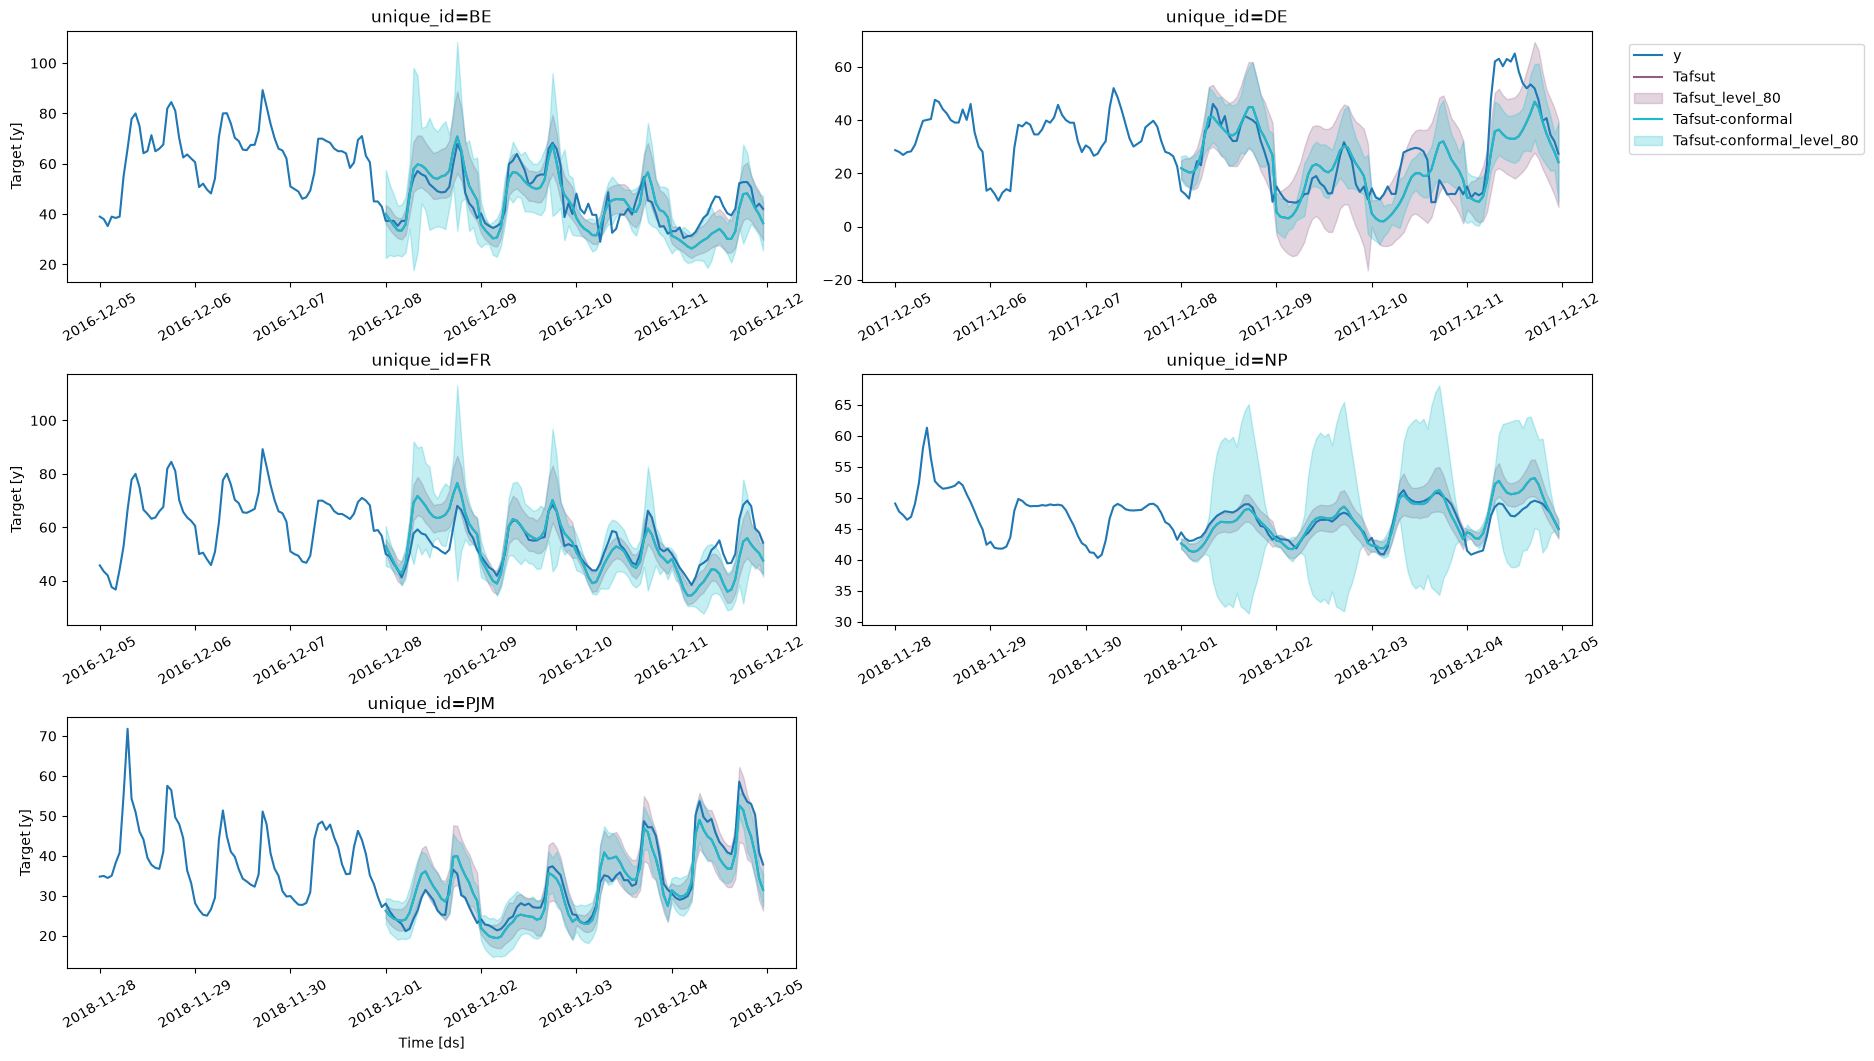

In [8]:
ff.plot(
    df,
    holdout_df.drop(columns=["cutoff", "y"]),
    models=["Tafsut", "Tafsut-conformal"],
    level=[80],
    max_insample_length=24 * 7,
)

## Evaluation

**Coverage** is the share of actuals that fall inside each interval; a well-calibrated 80% interval should
cover about 0.80. We also report **MASE** (point accuracy, identical within each native/conformal pair because
they share the point forecast) and **scaled CRPS** computed from the interval bounds.

In [9]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import coverage, mase, scaled_crps

In [10]:
eval_df = evaluate(
    holdout_df.drop(columns=["cutoff"]),
    train_df=df,
    metrics=[partial(mase, seasonality=24), scaled_crps, coverage],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.round(3)

metric,coverage_level80,coverage_level90,mase,scaled_crps
Tafsut,0.715,0.715,0.648,0.050
Tafsut-conformal,0.750,0.833,0.648,0.059
Chronos-2,0.729,0.865,0.677,0.054
Chronos-2-conformal,0.719,0.815,0.677,0.065


**Reading the table:**
- **Tafsut**'s native quantile head stops at the 0.1 / 0.9 knots, so its 90% interval is clamped to the 80% one
  and both cover the same share of actuals. The conformal copy is not bound by those knots: coverage rises at
  both levels and the 90% interval is genuinely wider than the 80% one.
- **Chronos-2**'s native quantiles are already about as well calibrated as the conformal ones here, so conformal
  intervals buy little for this model.
- Both conformal models still under-cover slightly. Seven calibration windows is a small sample; increasing
  `n_windows` trades compute for more stable intervals.
- MASE is identical within each pair because conformal calibration never changes the point forecast.

This holdout covers 4 days × 5 markets, so treat small differences as noise.

Interval **width** is the other half of the story: narrow intervals with low coverage are overconfident,
wide intervals with high coverage are conservative. Average width of the 80% interval per model:

In [11]:
model_names = [m.alias for m in models]
pd.Series(
    {m: (holdout_df[f"{m}-hi-80"] - holdout_df[f"{m}-lo-80"]).mean() for m in model_names},
    name="mean width (80%)",
).round(2)

Tafsut                 13.47
Tafsut-conformal       16.81
Chronos-2              14.65
Chronos-2-conformal    16.66
Name: mean width (80%), dtype: float64

## Forecast

With calibration validated, forecast the next 24 hours from the full history. Conformal models calibrate on
the last `n_windows` days of `df` before producing their intervals.

In [12]:
fcst_df = ff.forecast(df=df, h=h, level=level)
fcst_df.head()

,unique_id,ds,Tafsut,Tafsut-lo-80,Tafsut-hi-80,Tafsut-lo-90,Tafsut-hi-90,Tafsut-conformal,Tafsut-conformal-lo-90,Tafsut-conformal-lo-80,...,Chronos-2,Chronos-2-lo-80,Chronos-2-hi-80,Chronos-2-lo-90,Chronos-2-hi-90,Chronos-2-conformal,Chronos-2-conformal-lo-90,Chronos-2-conformal-lo-80,Chronos-2-conformal-hi-80,Chronos-2-conformal-hi-90
0,BE,2016-12-12 00:00:00,39.107590,35.773071,42.424500,35.773071,42.424500,39.107590,30.669209,32.127687,...,40.200974,36.950768,43.658497,35.418259,45.691681,40.200974,32.285516,33.046155,47.355792,48.116431
1,BE,2016-12-12 01:00:00,37.518028,34.333977,40.831589,34.333977,40.831589,37.518028,32.214356,33.042392,...,38.486259,35.187252,42.187817,33.727493,44.202404,38.486259,33.786692,34.868658,42.103861,43.185827
2,BE,2016-12-12 02:00:00,36.150246,33.190468,39.554028,33.190468,39.554028,36.150246,30.755640,31.355113,...,37.232536,33.829403,41.102200,32.455994,43.256252,37.232536,31.282653,31.512565,42.952507,43.182419
3,BE,2016-12-12 03:00:00,34.675610,31.934195,39.061707,31.934195,39.061707,34.675610,26.134026,28.130135,...,36.887932,32.792667,41.167854,31.135235,43.427158,36.887932,29.441453,31.243694,42.532170,44.334411
4,BE,2016-12-12 04:00:00,34.736134,31.831902,39.659538,31.831902,39.659538,34.736134,27.112179,28.190887,...,36.985832,33.181557,41.256485,31.680941,43.635120,36.985832,30.884007,31.594545,42.377119,43.087657


## Plot forecast

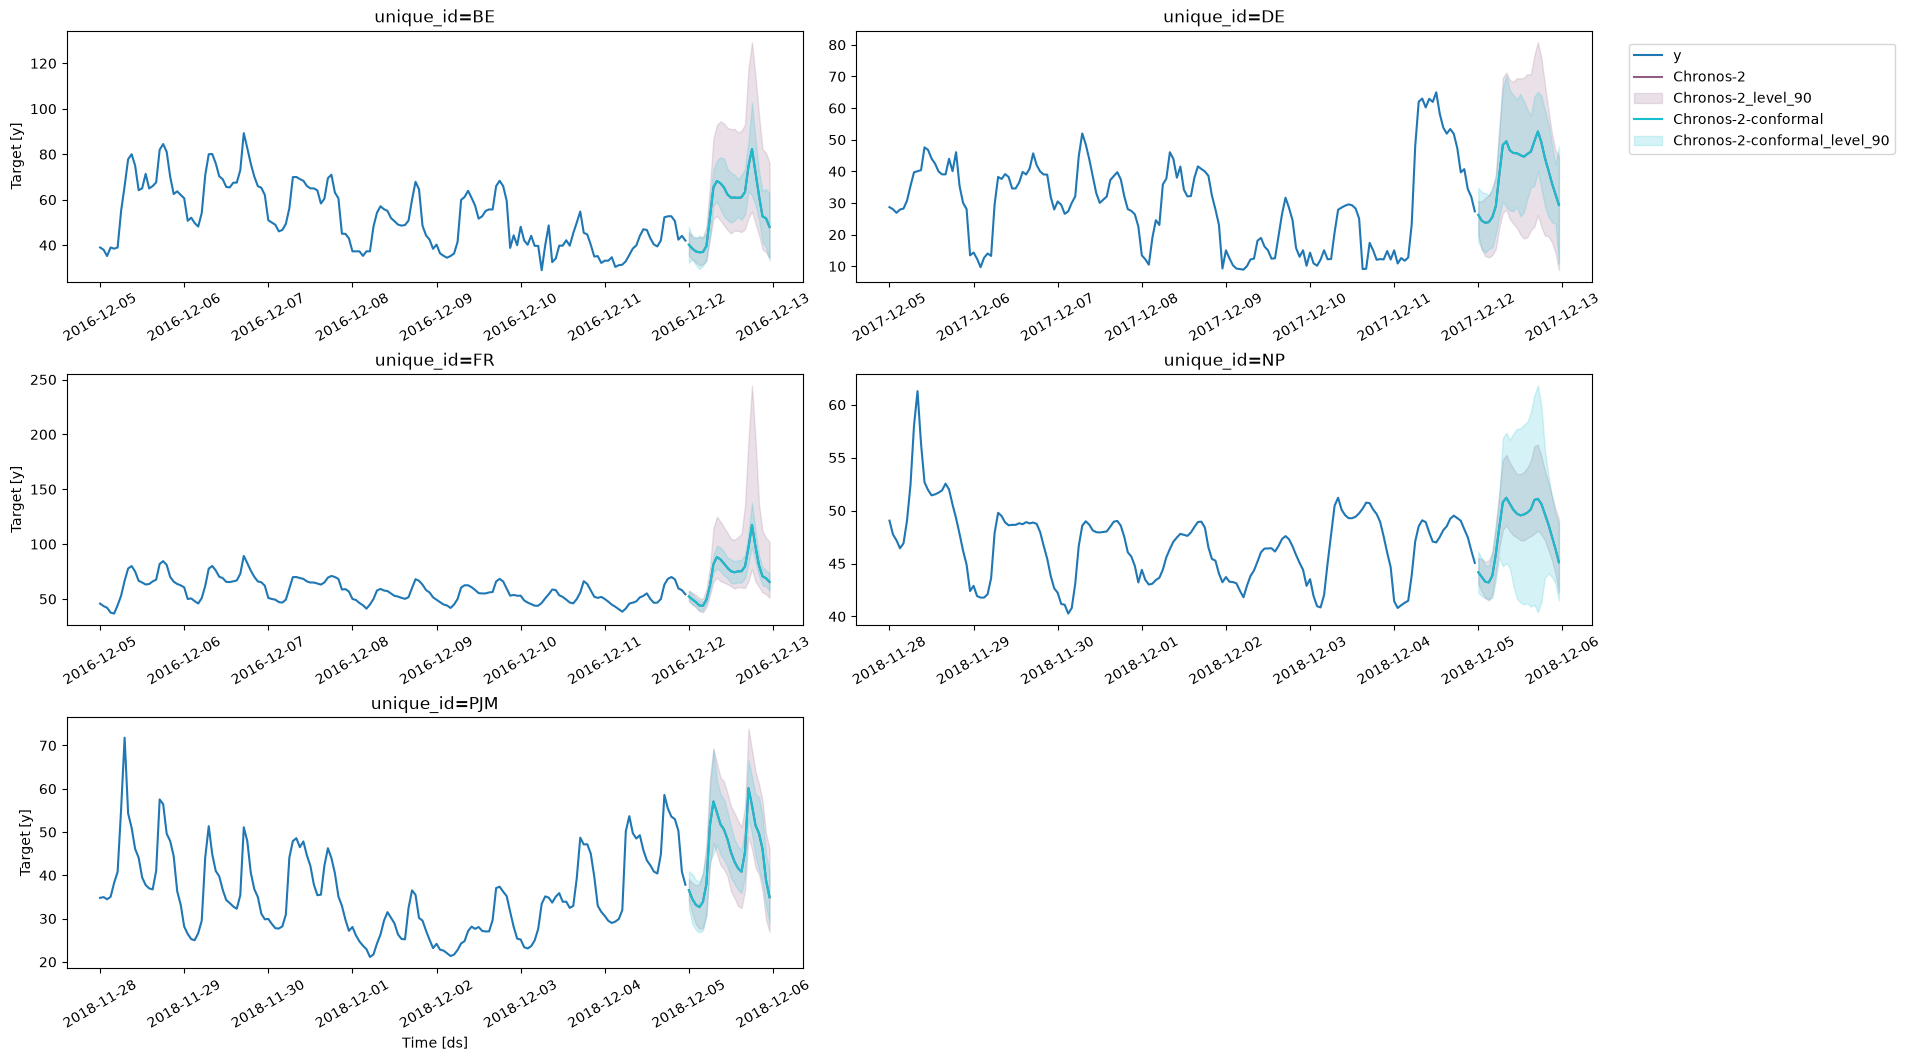

In [13]:
ff.plot(
    df,
    fcst_df,
    models=["Chronos-2", "Chronos-2-conformal"],
    level=[90],
    max_insample_length=24 * 7,
)